In [1]:
import sqlite3, pandas as pd
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
con = sqlite3.connect(":memory:")
df.to_sql("customers", con, index=False)
pd.read_sql("SELECT Contract, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY Contract", con)

,Contract,churn_rate
0,Month-to-month,0.427097
1,One year,0.112695
2,Two year,0.028319


In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## The data set includes information about:

* Customers who left within the last month – the column is called Churn
* Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
* Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
* Demographic info about customers – gender, age range, and if they have partners and dependents

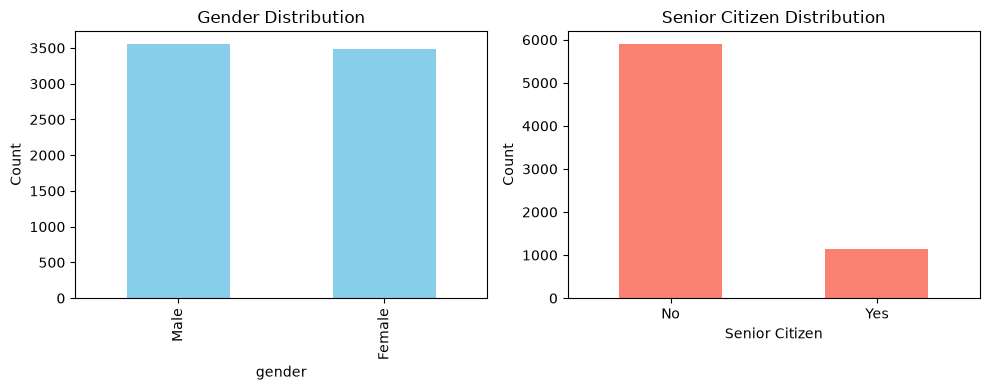

In [4]:
import matplotlib.pyplot as plt

# Create 1 row and 2 columns of plots (side-by-side)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

# First plot (Left)
df["gender"].value_counts().plot(kind="bar", ax=ax[0], color="skyblue")
ax[0].set_title("Gender Distribution")
ax[0].set_ylabel("Count")

# Second plot (Right)
df["SeniorCitizen"].map({0: "No", 1: "Yes"}).value_counts().plot(
    kind="bar", ax=ax[1], color="salmon"
)
ax[1].set_title("Senior Citizen Distribution")
ax[1].set_xlabel("Senior Citizen")
ax[1].set_ylabel("Count")
ax[1].tick_params(axis="x", rotation=0)

# Automatically adjust spacing so labels don't overlap
plt.tight_layout()
plt.show()

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
pd.read_sql("SELECT Dependents, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY Dependents", con)

,Dependents,churn_rate
0,No,0.312791
1,Yes,0.154502


In [7]:
pd.read_sql("SELECT Partner, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY Partner", con)

,Partner,churn_rate
0,No,0.329580
1,Yes,0.196649


## Finding 1: If they Customer doesn't have Partner/Dependents, His Churn_rate increases

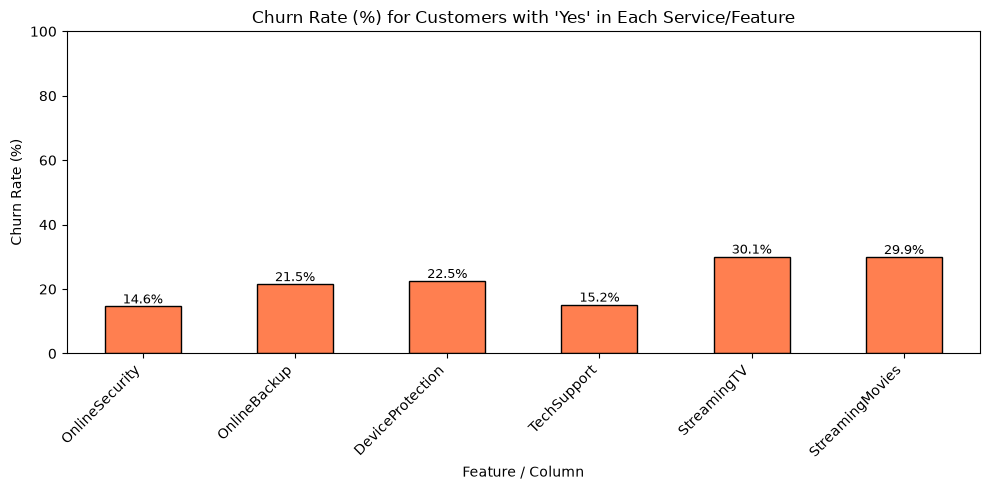

In [8]:
import matplotlib.pyplot as plt

# Create 1 row and 2 columns of plots (side-by-side)

cols = df.iloc[:, 9:15].columns
churn_rates = {}
for col in cols:
    yes_customers = df[df[col] == "Yes"]
    # Calculate percentage of "Yes" in the Churn column
    rate = (yes_customers["Churn"] == "Yes").mean() * 100
    churn_rates[col] = rate

# Convert to a Series for easy plotting
rates_series = pd.Series(churn_rates)

# 3. Plot the bar chart
plt.figure(figsize=(10, 5))
ax = rates_series.plot(kind="bar", color="coral", edgecolor="black")

plt.title("Churn Rate (%) for Customers with 'Yes' in Each Service/Feature")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Feature / Column")
plt.ylim(0, 100)  # Optional: sets y-axis from 0% to 100%
plt.xticks(rotation=45, ha="right")

# Optional: Add exact percentage labels on top of each bar
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [9]:
Rates = pd.DataFrame(rates_series)
Rates

,0
OnlineSecurity,14.611194
OnlineBackup,21.531494
DeviceProtection,22.502064
TechSupport,15.166341
StreamingTV,30.070188
StreamingMovies,29.941435


In [10]:
pd.read_sql("SELECT StreamingMovies, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY StreamingMovies", con)

,StreamingMovies,churn_rate
0,No,0.336804
1,No internet service,0.074050
2,Yes,0.299414


In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [13]:
pd.read_sql("SELECT InternetService, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY InternetService", con)

,InternetService,churn_rate
0,DSL,0.189591
1,Fiber optic,0.418928
2,No,0.074050


In [14]:
pd.read_sql("SELECT PhoneService, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY PhoneService", con)

,PhoneService,churn_rate
0,No,0.249267
1,Yes,0.267096


In [15]:
pd.read_sql("SELECT MultipleLines, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY MultipleLines", con)

,MultipleLines,churn_rate
0,No,0.250442
1,No phone service,0.249267
2,Yes,0.286099


In [16]:
pd.read_sql("SELECT PaymentMethod, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY PaymentMethod", con)

,PaymentMethod,churn_rate
0,Bank transfer (automatic),0.167098
1,Credit card (automatic),0.152431
2,Electronic check,0.452854
3,Mailed check,0.191067


In [17]:
pd.read_sql("SELECT PaperlessBilling, AVG(Churn='Yes') AS churn_rate FROM customers GROUP BY PaperlessBilling", con)

,PaperlessBilling,churn_rate
0,No,0.163301
1,Yes,0.335651


In [18]:
import pandas as pd

# Create tenure brackets (0-1 yr, 1-2 yrs, etc.)
bins = [0, 12, 24, 36, 48, 60, 72]
labels = ["0-12m", "13-24m", "25-36m", "37-48m", "49-60m", "61-72m"]
df["tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

# Calculate churn rate (%) per tenure group
cohort_churn = df.groupby("tenure_group", observed=False)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)
print(cohort_churn)

tenure_group
0-12m     47.438243
13-24m    28.710938
25-36m    21.634615
37-48m    19.028871
49-60m    14.423077
61-72m     6.609808
Name: Churn, dtype: float64


In [19]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [20]:
# Fill missing TotalCharges using MonthlyCharges * tenure
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])


In [21]:
df["TotalCharges"].dtype

dtype('float64')

In [22]:
pd.read_sql("SELECT PaymentMethod,Contract, AVG(Churn='Yes') AS churn_rate FROM customers WHERE PaymentMethod='Electronic check' GROUP BY PaymentMethod", con)

,PaymentMethod,Contract,churn_rate
0,Electronic check,Month-to-month,0.452854


In [24]:
# 1. Check customer counts per combination
counts = pd.crosstab(df["PaymentMethod"], df["Contract"])
print("--- Customer Counts ---")
print(counts)

# 2. Check churn rate (%) per combination
rates = pd.crosstab(
    df["PaymentMethod"],
    df["Contract"],
    values=(df["Churn"] == "Yes"),
    aggfunc="mean"
) * 100
print("\n--- Churn Rate (%) ---")
print(rates.round(1))

--- Customer Counts ---
Contract                   Month-to-month  One year  Two year
PaymentMethod                                                
Bank transfer (automatic)             589       391       564
Credit card (automatic)               543       398       581
Electronic check                     1850       347       168
Mailed check                          893       337       382

--- Churn Rate (%) ---
Contract                   Month-to-month  One year  Two year
PaymentMethod                                                
Bank transfer (automatic)            34.1       9.7       3.4
Credit card (automatic)              32.8      10.3       2.2
Electronic check                     53.7      18.4       7.7
Mailed check                         31.6       6.8       0.8


In [25]:
for col in ["tenure_group", "InternetService", "PaperlessBilling", "Partner", "Dependents"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()


--- tenure_group ---
tenure_group
0-12m     2186
61-72m    1407
13-24m    1024
25-36m     832
49-60m     832
37-48m     762
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- PaperlessBilling ---
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64



In [35]:
pd.read_sql("SELECT InternetService,Contract,COUNT(Contract) AS Contract_count, AVG(Churn='Yes') AS churn_rate FROM customers WHERE InternetService='Fiber optic' GROUP BY Contract", con)

,InternetService,Contract,Contract_count,churn_rate
0,Fiber optic,Month-to-month,2128,0.546053
1,Fiber optic,One year,539,0.192950
2,Fiber optic,Two year,429,0.072261


In [30]:
# 1. Check customer counts per combination
counts = pd.crosstab(df["InternetService"], df["Contract"])
print("--- Customer Counts ---")
print(counts)

# 2. Check churn rate (%) per combination
rates = pd.crosstab(
    df["InternetService"],
    df["Contract"],
    values=(df["Churn"] == "Yes"),
    aggfunc="mean"
) * 100
print("\n--- Churn Rate (%) ---")
print(rates.round(1))

--- Customer Counts ---
Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        1223       570       628
Fiber optic                2128       539       429
No                          524       364       638

--- Churn Rate (%) ---
Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        32.2       9.3       1.9
Fiber optic                54.6      19.3       7.2
No                         18.9       2.5       0.8


In [34]:
df = pd.read_sql(
    """
    SELECT InternetService, Churn, MonthlyCharges 
    FROM customers 
    WHERE InternetService = 'Fiber optic'
""",
    con,
)

result = df.groupby(['InternetService', 'Churn'], as_index=False)[
    'MonthlyCharges'
].median()
result

,InternetService,Churn,MonthlyCharges
0,Fiber optic,No,94.80
1,Fiber optic,Yes,87.55
